In [ ]:
# ------------------------------------------------------
# --------------- Play with Output! -------------------
# ------------------------------------------------------
# The purpose of this script is to play with some 
# ECCO-Darwin output to figure out what is going on and
# where and how and all the things! Trés exploratory!
#
# Notes:
# - Needs to run in ecco-darwin conda env
# - The picup files are like ROMS rst files and the output
#   files are in run/diags/ folders (I think)
#
# -----------------------------------------------------

In [47]:
# Load in the packages
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import xmitgcm
import ecco_v4_py as ecco
import MITgcmutils
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

## ECCO Darwin Output Files
 See here for legit/official/useful info: https://xmitgcm.readthedocs.io/en/latest/usage.html 

- STDOUT.* :
- STDERR.* :
- CO2_budg_2d.0000002192.data:
- CO2_budg_2d.0000002192.meta: 


#### <span style="color:forestgreen"> The Grid </span>

In [3]:
# Set the path to the lat/lon info 
grid_lonc = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/LONC.bin'
grid_long = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/LONG.bin'
grid_latc = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/LATC.bin'
grid_latc = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/LATG.bin'





In [15]:
# Try to read these files in?
lon = np.fromfile(grid_lonc, dtype=">f4")
lat = np.fromfile(grid_latc, dtype=">f4")

print("Longitude values:", lon.size)
print("Latitude values:", lat.size)
#print("Expected grid size:", ny * nx)


#grid_lonc = MITgcmutils.mds.rdmds('/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/LONC.bin')

#ecco.read_llc_to_compact(fdir='/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/', 
                                   #fname='LONC.bin')

Longitude values: 3128
Latitude values: 3128


In [17]:
print(lon[0])
print(lon[-1])
print(lat[0])
print(lat[-1])

-138.25752
-128.08562
75.23892
67.25099


#### <span style="color:brown"> CO2 </span>  
Load in the daily CO2 output from the model! Based on things being printed every 72 timesteps and output being daily, I am guessing the model timestep is 20 minutes? 

In [ ]:
# Get all the iterations 
CO2_itrs = MITgcmutils.mds.scanforfiles('/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/diags/daily/CO2')

# Load the output
CO2, CO2_its, CO2_meta = MITgcmutils.mds.rdmds('/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/diags/daily/CO2',
                            itrs=CO2_itrs, returnmeta=True)

In [6]:
CO2_meta

{'ndims': [2],
 'dataprec': ['float32'],
 'nrecords': [2],
 'missingvalue': [-999.0],
 'nflds': [2],
 'fldlist': ['fluxCO2', 'pCO2'],
 'dimlist': [46, 68],
 'timestepnumber': [72,
  144,
  216,
  288,
  360,
  432,
  504,
  576,
  648,
  720,
  792,
  864,
  936,
  1008,
  1080,
  1152,
  1224,
  1296,
  1368,
  1440,
  1512,
  1584,
  1656,
  1728,
  1800,
  1872,
  1944,
  2016,
  2088,
  2160,
  2192],
 'timeinterval': [[1200.0, 86400.0],
  [86400.0, 172800.0],
  [172800.0, 259200.0],
  [259200.0, 345600.0],
  [345600.0, 432000.0],
  [432000.0, 518400.0],
  [518400.0, 604800.0],
  [604800.0, 691200.0],
  [691200.0, 777600.0],
  [777600.0, 864000.0],
  [864000.0, 950400.0],
  [950400.0, 1036800.0],
  [1036800.0, 1123200.0],
  [1123200.0, 1209600.0],
  [1209600.0, 1296000.0],
  [1296000.0, 1382400.0],
  [1382400.0, 1468800.0],
  [1468800.0, 1555200.0],
  [1555200.0, 1641600.0],
  [1641600.0, 1728000.0],
  [1728000.0, 1814400.0],
  [1814400.0, 1900800.0],
  [1900800.0, 1987200.0],
  [1

In [19]:
# Look at the shape of the data to figure out what we have
# Returns [31 2, 68, 46] = [time, fluxCO2/pCO2, y, x]
np.shape(CO2)

# Pull out these dimensions 
ny, nx = CO2.shape[-2:]
print('ny: ', ny)
print('nx: ', nx)

ny:  68
nx:  46


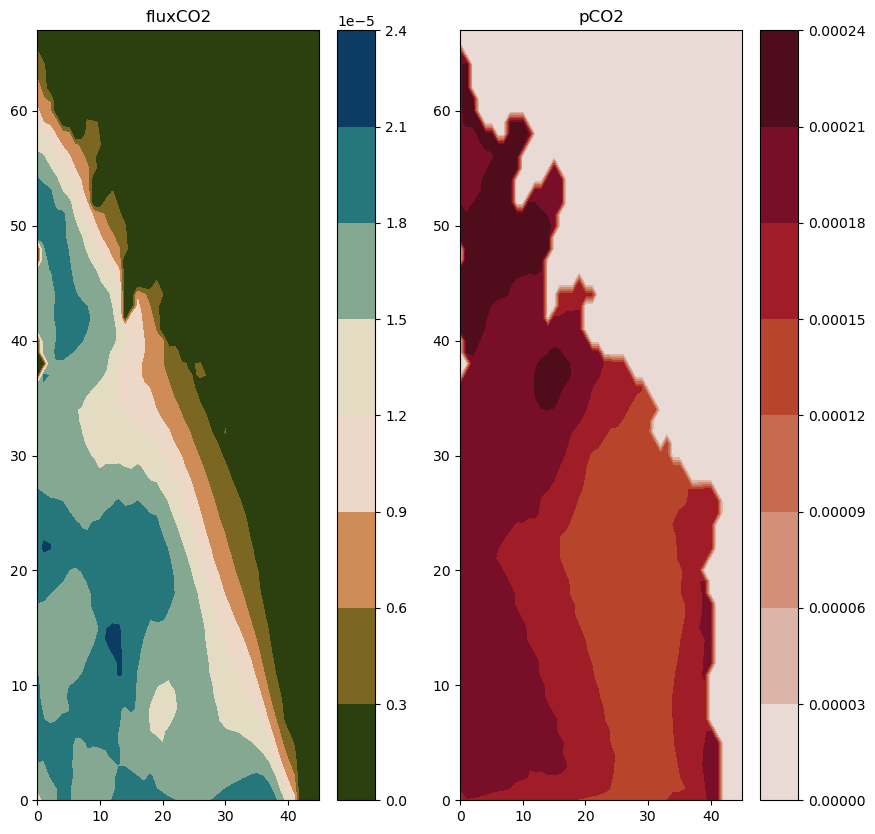

In [11]:
# Plot maps of CO2 flux and particulate 

fig, ax = plt.subplots(1,2, figsize=(10,10))

cs1 = ax[0].contourf(CO2[0,0,:,:], cmap=cmocean.cm.tarn)
ax[0].set_title('fluxCO2')
plt.colorbar(cs1, ax=ax[0], extend='both')

cs2 = ax[1].contourf(CO2[0,1,:,:], cmap=cmocean.cm.amp)
ax[1].set_title('pCO2')
plt.colorbar(cs2, ax=ax[1], extend='both')

In [20]:
# Reshape lat and lon to plot maps 
lon = lon.reshape(ny, nx)
lat = lat.reshape(ny, nx)

/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.1

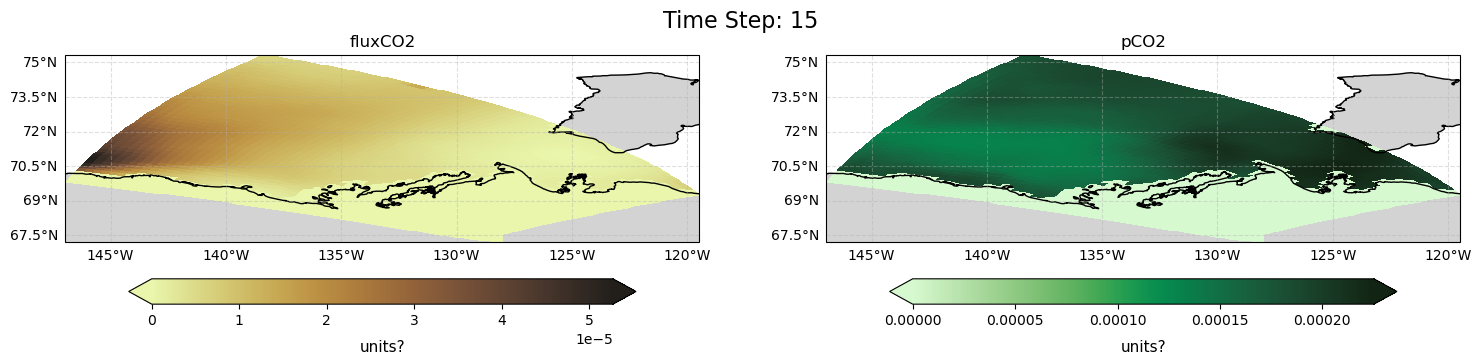

In [68]:
# Now try to plot these on a map

# Set the time to look at 
time_idx = 15

# Make the figure
fig, ax = plt.subplots(1, 2, figsize=(18,12), subplot_kw={"projection": ccrs.PlateCarree()})

# fluxCO2
cs1 = ax[0].pcolormesh(lon, lat, CO2[time_idx,0,:,:], cmap=cmocean.cm.turbid)
ax[0].set_title('fluxCO2')
#plt.colorbar(cs1, ax=ax[0], extend='both')

# pCO2
cs2 = ax[1].pcolormesh(lon, lat, CO2[time_idx,1,:,:], cmap=cmocean.cm.algae)
ax[1].set_title('pCO2')
#plt.colorbar(cs2, ax=ax[1], extend='both')

# Make the plots prettier
conts = [cs1, cs2]
labels = ['units?', 'units?']
for r in range(2):
    # Add coastline and land map
    ax[r].coastlines()
    ax[r].add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
    # Add gridlines
    gl = ax[r].gridlines(draw_labels=True, linestyle="--", alpha=0.4)
    # Remove labels from top and right 
    gl.top_labels = False
    gl.right_labels = False
    # Add a colorbar
    cbar = fig.colorbar(conts[r], ax=ax[r], orientation='horizontal', pad=0.04, shrink=0.8, extend='both')
    cbar.set_label(labels[r], fontsize=11, labelpad=8)

# Title object for showing time step
time_title = fig.suptitle(f'Time Step: ' + str(time_idx), fontsize=16, y=0.45)

plt.show()



In [71]:
# Make an inline movie version! 

# Make the figure - Initialize with the first time step
fig, ax = plt.subplots(1, 2, figsize=(18,12), subplot_kw={"projection": ccrs.PlateCarree()},
                       constrained_layout=True)

# fluxCO2
cs1 = ax[0].pcolormesh(lon, lat, CO2[0,0,:,:], vmin=0, vmax=2e-5, cmap=cmocean.cm.turbid)
ax[0].set_title('fluxCO2')
#plt.colorbar(cs1, ax=ax[0], extend='both')

# pCO2
cs2 = ax[1].pcolormesh(lon, lat, CO2[0,1,:,:], vmin=0.0001, vmax=0.0002, cmap=cmocean.cm.algae)
ax[1].set_title('pCO2')
#plt.colorbar(cs2, ax=ax[1], extend='both')

# Make the plots prettier
conts = [cs1, cs2]
labels = ['units?', 'units?']
vmin = [0, 0.0001]
vmax = [2e-5, 0.0002]
for r in range(2):
    # Add coastline and land map
    ax[r].coastlines()
    ax[r].add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
    # Add gridlines
    gl = ax[r].gridlines(draw_labels=True, linestyle="--", alpha=0.4)
    # Remove labels from top and right 
    gl.top_labels = False
    gl.right_labels = False
    # Add a colorbar
    cbar = fig.colorbar(conts[r], ax=ax[r], orientation='horizontal', pad=0.04, shrink=0.8, extend='both')
    cbar.set_label(labels[r], fontsize=11, labelpad=8)

# Title object for showing time step
time_title = fig.suptitle(f'Time Index: 0', fontsize=16, y=0.45)

# Update function called for each frame
def update(frame):
    # Update pcolormesh data using set_array (flattened 2D array)
    cs1.set_array(CO2[frame, 0, :, :].ravel())
    cs2.set_array(CO2[frame, 1, :, :].ravel())
    time_title.set_text(f'Time Index: {frame}')
    return cs1, cs2, time_title

# Create animation, looping through time
num_frames = CO2.shape[0]
anim = FuncAnimation(fig, update, frames=range(num_frames), interval=200, blit=False)

# Close plot to prevent static duplicate display in Jupyter
plt.close(fig)

# Display inline movie player
HTML(anim.to_html5_video())


/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.1

#### <span style="color:darkorchid"> DIC </span>  
Load in the daily DIC output from the model!

In [62]:
# Get all the iterations 
DIC_itrs = MITgcmutils.mds.scanforfiles('/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/diags/daily/DIC')

# Load the output
DIC, DIC_its, DIC_meta = MITgcmutils.mds.rdmds('/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/diags/daily/DIC',
                            itrs=DIC_itrs, returnmeta=True)

In [64]:
DIC_meta

{'ndims': [3],
 'dataprec': ['float32'],
 'nrecords': [2],
 'missingvalue': [-999.0],
 'nflds': [2],
 'fldlist': ['TRAC01', 'TRAC19'],
 'dimlist': [46, 68, 44],
 'timestepnumber': [72,
  144,
  216,
  288,
  360,
  432,
  504,
  576,
  648,
  720,
  792,
  864,
  936,
  1008,
  1080,
  1152,
  1224,
  1296,
  1368,
  1440,
  1512,
  1584,
  1656,
  1728,
  1800,
  1872,
  1944,
  2016,
  2088,
  2160,
  2192],
 'timeinterval': [[1200.0, 86400.0],
  [86400.0, 172800.0],
  [172800.0, 259200.0],
  [259200.0, 345600.0],
  [345600.0, 432000.0],
  [432000.0, 518400.0],
  [518400.0, 604800.0],
  [604800.0, 691200.0],
  [691200.0, 777600.0],
  [777600.0, 864000.0],
  [864000.0, 950400.0],
  [950400.0, 1036800.0],
  [1036800.0, 1123200.0],
  [1123200.0, 1209600.0],
  [1209600.0, 1296000.0],
  [1296000.0, 1382400.0],
  [1382400.0, 1468800.0],
  [1468800.0, 1555200.0],
  [1555200.0, 1641600.0],
  [1641600.0, 1728000.0],
  [1728000.0, 1814400.0],
  [1814400.0, 1900800.0],
  [1900800.0, 1987200.0],

In [ ]:
# Get the dimensions of DIC
# [31,2,44,68,46] = [time, tracer01/tracer19, z, y, x] but note y = longitudes and x = latitudes 
# Also note tracer01 = DIC, tracer19 = Alk
np.shape(DIC)

(31, 2, 44, 68, 46)

/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.1

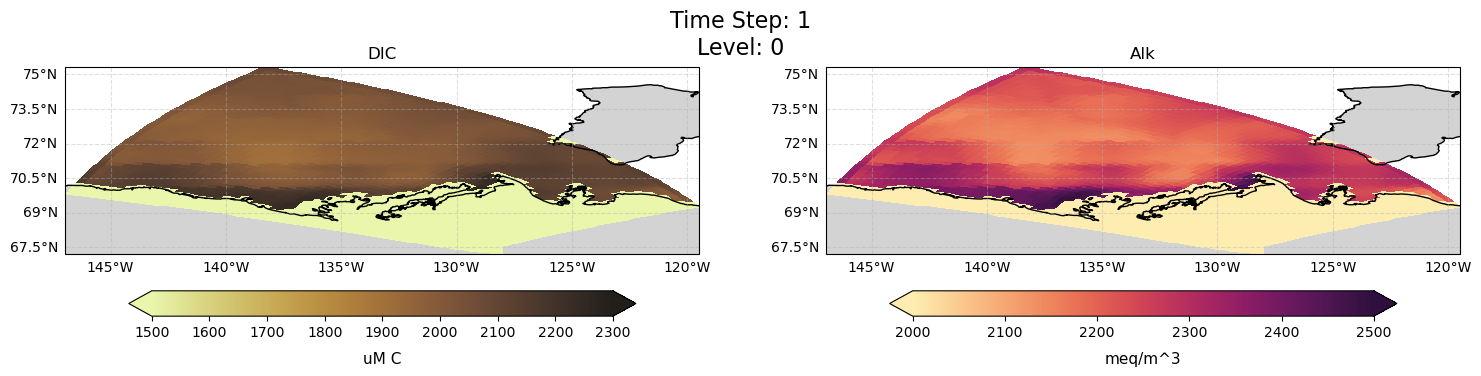

In [87]:
# Now try to plot these on a map

# Set the time to look at 
time_idx = 1

# Set the vertical level 
z_lev = 0

# Make the figure
fig, ax = plt.subplots(1, 2, figsize=(18,12), subplot_kw={"projection": ccrs.PlateCarree()})

# fluxCO2
cs1 = ax[0].pcolormesh(lon, lat, DIC[time_idx,0,z_lev,:,:], cmap=cmocean.cm.turbid, vmin=1500, vmax=2300)
ax[0].set_title('DIC')
#plt.colorbar(cs1, ax=ax[0], extend='both')

# pCO2
cs2 = ax[1].pcolormesh(lon, lat, DIC[time_idx,1,z_lev,:,:], cmap=cmocean.cm.matter, vmin=2000, vmax=2500)
ax[1].set_title('Alk')
#plt.colorbar(cs2, ax=ax[1], extend='both')

# Make the plots prettier
conts = [cs1, cs2]
labels = ['uM C', 'meq/m^3']
for r in range(2):
    # Add coastline and land map
    ax[r].coastlines()
    ax[r].add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
    # Add gridlines
    gl = ax[r].gridlines(draw_labels=True, linestyle="--", alpha=0.4)
    # Remove labels from top and right 
    gl.top_labels = False
    gl.right_labels = False
    # Add a colorbar
    cbar = fig.colorbar(conts[r], ax=ax[r], orientation='horizontal', pad=0.04, shrink=0.8, extend='both')
    cbar.set_label(labels[r], fontsize=11, labelpad=8)

# Title object for showing time step
time_title = fig.suptitle(f'Time Step: ' + str(time_idx) + '\nLevel: ' + str(z_lev), fontsize=16, y=0.46)

plt.show()

In [90]:
# Make a movie to see !

# Set the vertical level 
z_lev = 0

# Make the figure
fig, ax = plt.subplots(1, 2, figsize=(18,12), subplot_kw={"projection": ccrs.PlateCarree()})

# fluxCO2
cs1 = ax[0].pcolormesh(lon, lat, DIC[time_idx,0,z_lev,:,:], cmap=cmocean.cm.turbid, vmin=1500, vmax=2300)
ax[0].set_title('DIC')
#plt.colorbar(cs1, ax=ax[0], extend='both')

# pCO2
cs2 = ax[1].pcolormesh(lon, lat, DIC[time_idx,1,z_lev,:,:], cmap=cmocean.cm.matter, vmin=2000, vmax=2500)
ax[1].set_title('Alk')
#plt.colorbar(cs2, ax=ax[1], extend='both')

# Make the plots prettier
conts = [cs1, cs2]
labels = ['uM C', 'meq/m^3']
for r in range(2):
    # Add coastline and land map
    ax[r].coastlines()
    ax[r].add_feature(cfeature.LAND, facecolor="lightgray", zorder=0)
    # Add gridlines
    gl = ax[r].gridlines(draw_labels=True, linestyle="--", alpha=0.4)
    # Remove labels from top and right 
    gl.top_labels = False
    gl.right_labels = False
    # Add a colorbar
    cbar = fig.colorbar(conts[r], ax=ax[r], orientation='horizontal', pad=0.04, shrink=0.8, extend='both')
    cbar.set_label(labels[r], fontsize=11, labelpad=8)

# Title object for showing time step
time_title = fig.suptitle(f'Time Step: ' + str(time_idx) + '\nLevel: ' + str(z_lev), fontsize=16, y=0.46)

# Update function called for each frame
def update(frame):
    # Update pcolormesh data using set_array (flattened 2D array)
    cs1.set_array(DIC[frame, 0, z_lev, :, :].ravel())
    cs2.set_array(DIC[frame, 1, z_lev, :, :].ravel())
    time_title.set_text(f'Time Step: ' + str(time_idx) + '\nLevel: ' + str(z_lev))
    return cs1, cs2, time_title

# Create animation, looping through time
num_frames = DIC.shape[0]
anim = FuncAnimation(fig, update, frames=range(num_frames), interval=200, blit=False)

# Close plot to prevent static duplicate display in Jupyter
plt.close(fig)

# Display inline movie player
HTML(anim.to_html5_video())



/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/bundzis/miniconda3/envs/ecco-darwin/lib/python3.1

#### <span style="color:deeppink"> Tracers </span>

In [5]:
# Read in the tracers
tracer_01 = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/pickup_ptracers.0000000001'
tracer_data, tracer_its, tracer_meta = MITgcmutils.mds.rdmds(fnamearg=tracer_01, returnmeta=True)


In [6]:
tracer_meta

{'ndims': [3],
 'dataprec': ['float64'],
 'nrecords': [32],
 'nflds': [32],
 'fldlist': ['pTr01',
  'pTr02',
  'pTr03',
  'pTr04',
  'pTr05',
  'pTr06',
  'pTr07',
  'pTr08',
  'pTr09',
  'pTr10',
  'pTr11',
  'pTr12',
  'pTr13',
  'pTr14',
  'pTr15',
  'pTr16',
  'pTr17',
  'pTr18',
  'pTr19',
  'pTr20',
  'pTr21',
  'pTr22',
  'pTr23',
  'pTr24',
  'pTr25',
  'pTr26',
  'pTr27',
  'pTr28',
  'pTr29',
  'pTr30',
  'pTr31',
  'pTr32'],
 'dimlist': [46, 68, 44],
 'timestepnumber': [78912],
 'timeinterval': [[94694400.0]]}

Copied names and units for tracers from data.ptracers:  

PTRACERS_names( 1)= 'DIC',    
 PTRACERS_names( 2)= 'NO3',    
 PTRACERS_names( 3)= 'NO2',    
 PTRACERS_names( 4)= 'NH4',    
 PTRACERS_names( 5)= 'PO4',    
 PTRACERS_names( 6)= 'FeT',    
 PTRACERS_names( 7)= 'SiO2',    
 PTRACERS_names( 8)= 'DOC',    
 PTRACERS_names( 9)= 'tDOC',    
 PTRACERS_names(10)= 'DON',    
 PTRACERS_names(11)= 'DOP',    
 PTRACERS_names(12)= 'DOFe',    
 PTRACERS_names(13)= 'POC',    
 PTRACERS_names(14)= 'PON',    
 PTRACERS_names(15)= 'POP',    
 PTRACERS_names(16)= 'POFe',    
 PTRACERS_names(17)= 'POSi',    
 PTRACERS_names(18)= 'PIC',    
 PTRACERS_names(19)= 'ALK',    
 PTRACERS_names(20)= 'O2',    
 PTRACERS_names(21)= 'c01',    
 PTRACERS_names(22)= 'c02',    
 PTRACERS_names(23)= 'c03',    
 PTRACERS_names(24)= 'c04',    
 PTRACERS_names(25)= 'c05',    
 PTRACERS_names(26)= 'c06',    
 PTRACERS_names(27)= 'c07',    
 PTRACERS_names(28)= 'Chl01',    
 PTRACERS_names(29)= 'Chl02',    
 PTRACERS_names(30)= 'Chl03',    
 PTRACERS_names(31)= 'Chl04',    
 PTRACERS_names(32)= 'Chl05',    
#
 PTRACERS_units( 1)= 'uM C'    
 PTRACERS_units( 2)= 'uM N'    
 PTRACERS_units( 3)= 'uM N'    
 PTRACERS_units( 4)= 'uM N'    
 PTRACERS_units( 5)= 'uM P'    
 PTRACERS_units( 6)= 'uM Fe'    
 PTRACERS_units( 7)= 'uM Si'    
 PTRACERS_units( 8)= 'uM C'    
 PTRACERS_units( 9)= 'uM C'    
 PTRACERS_units(10)= 'uM N'    
 PTRACERS_units(11)= 'uM P'    
 PTRACERS_units(12)= 'uM Fe'    
 PTRACERS_units(13)= 'uM C'    
 PTRACERS_units(14)= 'uM N'    
 PTRACERS_units(15)= 'uM P'    
 PTRACERS_units(16)= 'uM Fe'    
 PTRACERS_units(17)= 'uM Si'    
 PTRACERS_units(18)= 'uM C'    
 PTRACERS_units(19)= 'meq/m^3'    
 PTRACERS_units(20)= 'uM O'    
 PTRACERS_units(21)= 'uM C'    
 PTRACERS_units(22)= 'uM C'    
 PTRACERS_units(23)= 'uM C'    
 PTRACERS_units(24)= 'uM C'    
 PTRACERS_units(25)= 'uM C'    
 PTRACERS_units(26)= 'uM C'    
 PTRACERS_units(27)= 'uM C'    
 PTRACERS_units(28)= 'mg/m^3'    
 PTRACERS_units(29)= 'mg/m^3'    
 PTRACERS_units(30)= 'mg/m^3'    
 PTRACERS_units(31)= 'mg/m^3'    
 PTRACERS_units(32)= 'mg/m^3'    

In [7]:
# What is the shape of the tracers?
#[32, 44, 68, 46] = [tracer, z, x?, y?] (all for one time step)
# llc270 has 44 evenly-spaced verticla levels, x and y are for the llc20 tile 
# so x is actually decreasing latitude and y is longitude 
np.shape(tracer_data)

(32, 44, 68, 46)

Text(0.5, 1.0, 'FeT (uM Fe)')

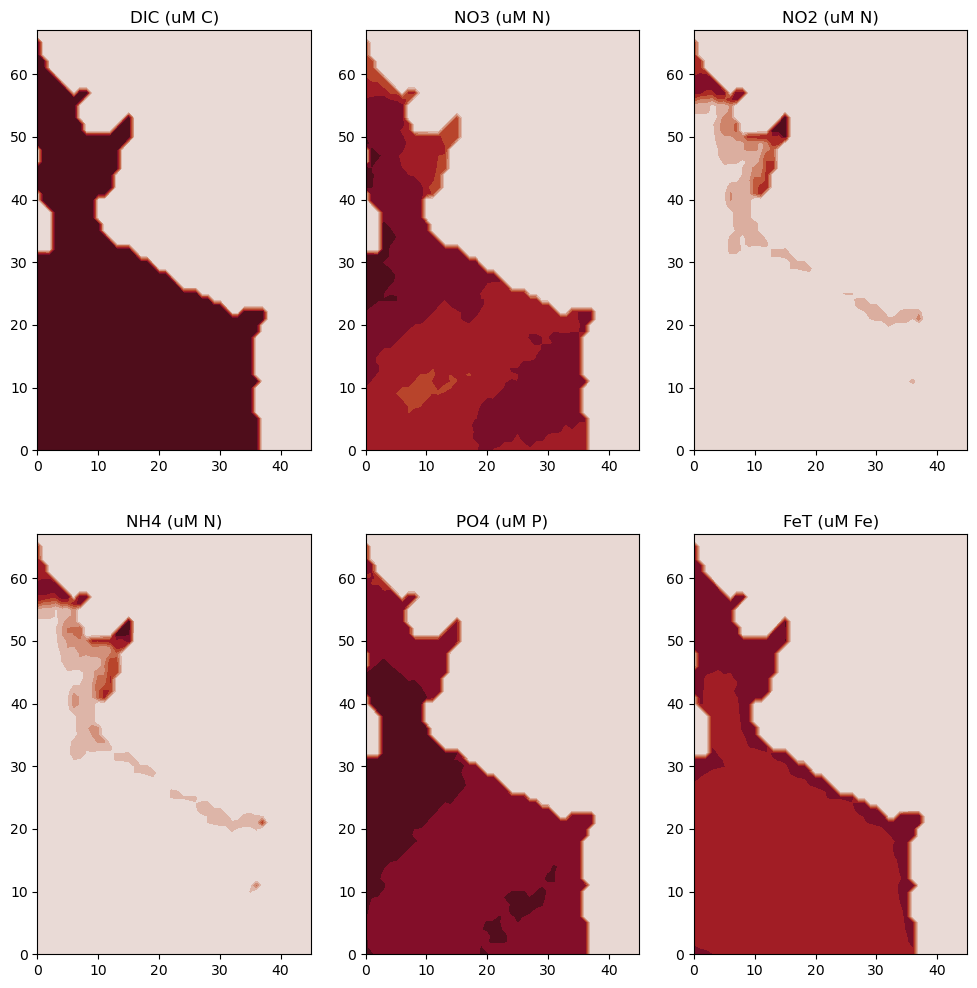

In [8]:
# Try to plot this?

# Set the vertical level
z_lev = 10

# Set the titles 
tracer_name = ['DIC', 'NO3', 'NO2', 'NH4', 'PO4', 'FeT']

# Make the figure
fig, ax = plt.subplots(2, 3, figsize=(12,12))

# Tracer 01 = DIC
cs1 = ax[0,0].contourf(tracer_data[0,z_lev,:,:], cmap=cmocean.cm.amp)
ax[0,0].set_title('DIC (uM C)')
#ax[0,0].yaxis.set_inverted(True)
# Tracer 02 = NO3
cs1 = ax[0,1].contourf(tracer_data[1,z_lev,:,:], cmap=cmocean.cm.amp)
ax[0,1].set_title('NO3 (uM N)')
# Tracer 03 = NO2
cs1 = ax[0,2].contourf(tracer_data[2,z_lev,:,:], cmap=cmocean.cm.amp)
ax[0,2].set_title('NO2 (uM N)')
# Tracer 04 = NH4
cs1 = ax[1,0].contourf(tracer_data[3,z_lev,:,:], cmap=cmocean.cm.amp)
ax[1,0].set_title('NH4 (uM N)')
# Tracer 05 = PO4
cs1 = ax[1,1].contourf(tracer_data[4,z_lev,:,:], cmap=cmocean.cm.amp)
ax[1,1].set_title('PO4 (uM P)')
# Tracer 06 = FeT
cs1 = ax[1,2].contourf(tracer_data[5,z_lev,:,:], cmap=cmocean.cm.amp)
ax[1,2].set_title('FeT (uM Fe)')

# Add colorbars 

Okay! So I think this is showing the different concentrations of the tracers at one time step (the one loaded above) at vertical level 10 (with 1 being the top of the water column/opposite of ROMS I think). I think it is oriented in the same way as Tile 6 in llc270 (https://ecco-v4-python-tutorial.readthedocs.io/ECCO_v4_Interpolating_Fields_to_LatLon_Grid.html). So north is to the left in the orientation of these plots!

In [9]:
# Can we plot this on a map with lat lon?

#### <span style="color:Blue"> Sea Ice </span>

In [10]:
# Read in sea ice things
sea_ice_01 = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/pickup_seaice.0000000001'
sea_ice_data, sea_ice_its, sea_ice_meta = MITgcmutils.mds.rdmds(fnamearg=sea_ice_01, returnmeta=True)

In [11]:
sea_ice_meta

{'ndims': [2],
 'dataprec': ['float64'],
 'nrecords': [6],
 'nflds': [6],
 'fldlist': ['siTICE', 'siAREA', 'siHEFF', 'siHSNOW', 'siUICE', 'siVICE'],
 'dimlist': [46, 68],
 'timestepnumber': [78841],
 'timeinterval': [[94609200.0]]}

In [12]:
# Print the shape of the data
np.shape(sea_ice_data)

(6, 68, 46)

Text(0.5, 1.0, 'V Ice Velocity ()')

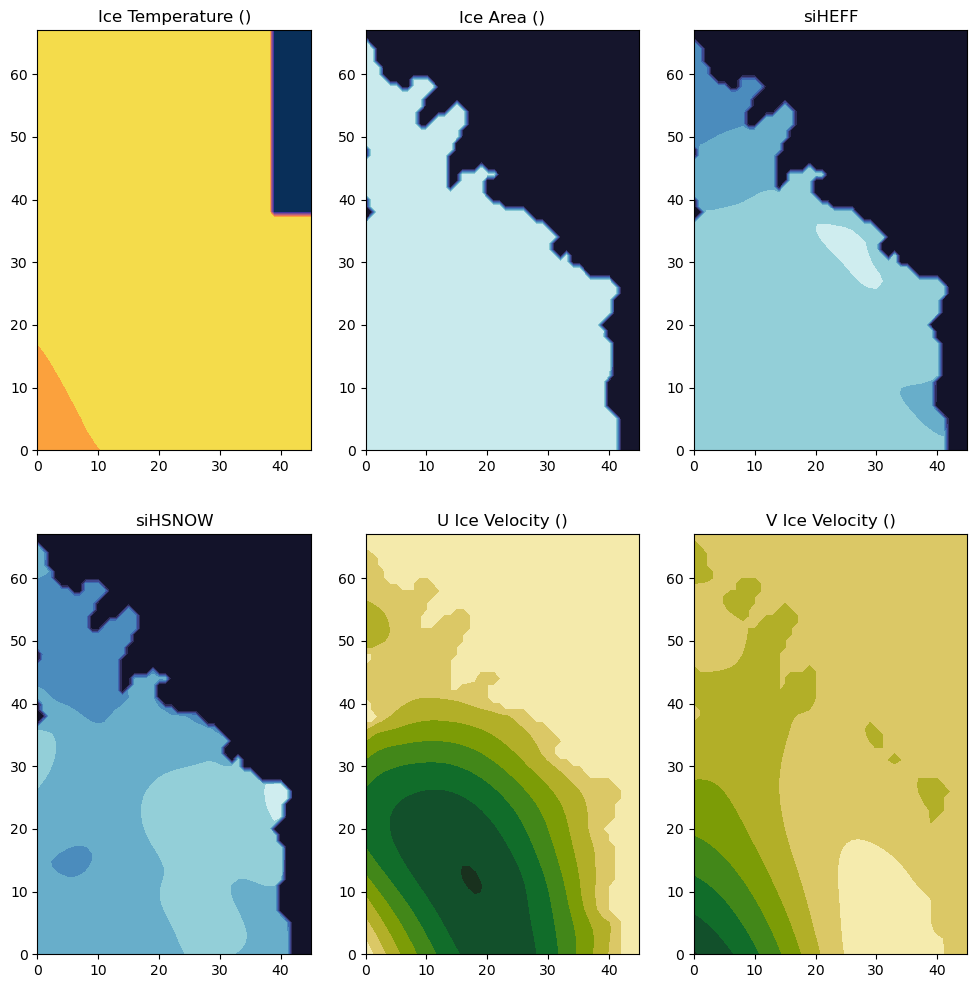

In [13]:
# Make a plot of the things
# Make the figure
fig, ax = plt.subplots(2, 3, figsize=(12,12))

# Tracer 01 = DIC
cs1 = ax[0,0].contourf(sea_ice_data[0,:,:], cmap=cmocean.cm.thermal)
ax[0,0].set_title('Ice Temperature ()')
#ax[0,0].yaxis.set_inverted(True)
# Tracer 02 = NO3
cs1 = ax[0,1].contourf(sea_ice_data[1,:,:], cmap=cmocean.cm.ice)
ax[0,1].set_title('Ice Area ()')
# Tracer 03 = NO2
cs1 = ax[0,2].contourf(sea_ice_data[2,:,:], cmap=cmocean.cm.ice)
ax[0,2].set_title('siHEFF')
# Tracer 04 = NH4
cs1 = ax[1,0].contourf(sea_ice_data[3,:,:], cmap=cmocean.cm.ice)
ax[1,0].set_title('siHSNOW')
# Tracer 05 = PO4
cs1 = ax[1,1].contourf(sea_ice_data[4,:,:], cmap=cmocean.cm.speed)
ax[1,1].set_title('U Ice Velocity ()')
# Tracer 06 = FeT
cs1 = ax[1,2].contourf(sea_ice_data[5,:,:], cmap=cmocean.cm.speed)
ax[1,2].set_title('V Ice Velocity ()')

# Add colorbars 


In [14]:
# Since pickup files are like restart files, try to find and 
# read in files that have a timeseries of things...

#### <span style="color:purple"> Smooth 3D norm? </span>

In [17]:
smooth_3d_norm,smooth3d_its,smooth3d_meta = MITgcmutils.mds.rdmds('/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/smooth3Dnorm001',
                                                                  returnmeta=True)

In [19]:
smooth3d_meta

{'ndims': [3],
 'dataprec': ['float32'],
 'nrecords': [1],
 'dimlist': [46, 68, 44],
 'timestepnumber': [1]}

In [23]:
smooth3d_its

[-1]

In [20]:
np.shape(smooth_3d_norm)

(44, 68, 46)

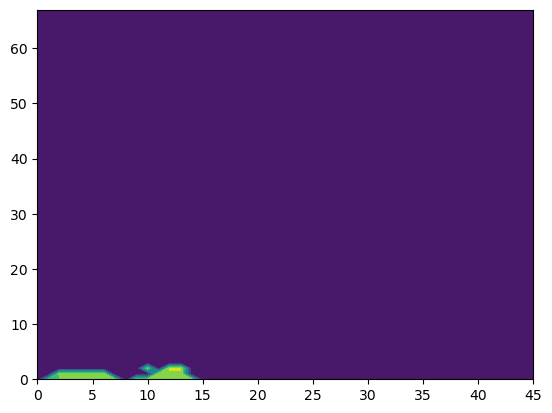

In [22]:
fig, ax = plt.subplots()

ax.contourf(smooth_3d_norm[43,:,:])

#### <span style="color:yellow"> Not Working but Maybe Useful Later </span>

In [ ]:
# Load in the model output? (this does not work)
# Where/what is the output...
data_dir = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run'

# Load with xmitgcm
model_output = xmitgcm.open_mdsdataset(data_dir=data_dir, prefix=['pickup', 'pickup_darwin'])


In [ ]:
# Look at it 
# Is it global? What are the coordinates? Is it giant?